# Two-zone model: UltraNest and MCMC

Nested sampling of the two-zone model from notebook 02: first with all free parameters, then a reduced run with
7 parameters, and an MCMC with the same 7 parameters so that Minuit, MCMC and UltraNest can be compared directly.
The sampling takes hours; the outputs shown are from my run, and the chains are in `results/two_zone/`.

In [ ]:
import os
os.makedirs('results/two_zone', exist_ok=True)
os.chdir('results/two_zone')            # everything this model reads and writes lives here

## Ultranest nested sampling of the two-zone model
Follows the reference script's ultranest pattern: - load data, build fit_mask - load best-fit composite model (TwoZone_final.pkl) - freeze ALL params, then free a chosen subset - prior_transform / log_likelihood over those free params - ReactiveNestedSampler + SliceSampler CHANGES vs reference: - fit_mask lower bound = 1e8 Hz (includes the 2 radio points) - free_params span BOTH jet_leptonic and jet_extended - log_likelihood sets params on the correct jet for each name No analysis after sampler.run() / print_results(), per request.

In [19]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import ultranest
import ultranest.stepsampler
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

# 1. LOAD DATA (same pattern as Parts 1-3)
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)

# fit_mask: 1e8 Hz lower bound -> INCLUDES the 2 radio points
# (~1.4e9 and ~4.85e9 Hz), unlike the reference's 1e10 cut.
fit_mask = (nu_obs >= 1e8) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

print(">>> Checkpoint U4.1: Data loaded, radio points included")
print(f"    N points in fit: {len(nu_obs)}")
print(f"    Radio points (<1e10 Hz): {nu_obs[nu_obs < 1e10]}")

# 2. LOAD TWO-ZONE BEST-FIT MODEL
fit_model = FitModel.load_model('TwoZone_final.pkl')
fit_model.eval()

print(">>> Checkpoint U4.2: Loaded TwoZone_final.pkl")

# Freeze ALL params on both jets first
for par in fit_model.jet_leptonic.parameters.par_array:
    par.frozen = True
for par in fit_model.jet_extended.parameters.par_array:
    par.frozen = True

# Free parameters: Zone1 core physics + Zone2 normalization
# (mirrors Part 3's free set, minus T_DT which we fix as in
#  the reference, at its Part-3 best-fit value)
T_DT_FIXED = fit_model.jet_leptonic.parameters.T_DT.val
fit_model.jet_leptonic.parameters.T_DT.val = T_DT_FIXED

free_params_zone1 = ['B', 'BulkFactor', 'N', 'gamma_break', 'M_BH', 'L_Disk',
                      'p', 'p_1', 'R_H', 'gmin']
free_params_zone2 = ['N', 'B']

for name in free_params_zone1:
    fit_model.jet_leptonic.parameters.get_par_by_name(name).frozen = False
for name in free_params_zone2:
    fit_model.jet_extended.parameters.get_par_by_name(name).frozen = False

# free_params: tuples of (jet_name, param_name) to disambiguate
# N and B which exist on both jets
free_params = (
    [('jet_leptonic', n) for n in free_params_zone1] +
    [('jet_extended', n) for n in free_params_zone2]
)
param_labels = [f"{jet}.{name}" for jet, name in free_params]

print(">>> Checkpoint U4.3: Free parameters configured")
print(f"    T_DT fixed at {T_DT_FIXED:.4f} K")
for jet, name in free_params:
    print(f"    {jet}.{name} = "
          f"{getattr(fit_model, jet).parameters.get_par_by_name(name).val:.4e}")

# Prior ranges: centered on Part-3 best-fit values, with
# physically motivated widths matching the fit_range bounds
# used in Part 3.
prior_mins = np.array([
    0.010,    # jet_leptonic.B
    10.0,     # jet_leptonic.BulkFactor
    400.0,    # jet_leptonic.N
    200.0,    # jet_leptonic.gamma_break
    5.0e8,    # jet_leptonic.M_BH
    1.0e46,   # jet_leptonic.L_Disk
    1.0,      # jet_leptonic.p
    2.5,      # jet_leptonic.p_1
    5.0e17,   # jet_leptonic.R_H
    1.0,      # jet_leptonic.gmin
    1.0e-3,   # jet_extended.N
    1.0e-4,   # jet_extended.B
])
prior_maxs = np.array([
    0.100,    # jet_leptonic.B
    25.0,     # jet_leptonic.BulkFactor
    2000.0,   # jet_leptonic.N
    3000.0,   # jet_leptonic.gamma_break
    2.0e9,    # jet_leptonic.M_BH
    5.0e46,   # jet_leptonic.L_Disk
    1.8,      # jet_leptonic.p
    3.8,      # jet_leptonic.p_1
    3.0e18,   # jet_leptonic.R_H
    50.0,     # jet_leptonic.gmin
    10.0,     # jet_extended.N
    5.0e-2,   # jet_extended.B
])

assert len(prior_mins) == len(free_params)
assert len(prior_maxs) == len(free_params)

def prior_transform(cube):
    return prior_mins + cube * (prior_maxs - prior_mins)

def get_composite_flux(nu_target):
    fit_model.eval()
    nu_grid   = fit_model.SED.nu.value
    flux_grid = fit_model.SED.nuFnu.value
    good      = np.isfinite(flux_grid) & np.isfinite(nu_grid) & (nu_grid > 0)
    nu_g      = nu_grid[good]
    fl_g      = flux_grid[good]
    idx       = np.argsort(nu_g)
    return np.interp(nu_target, nu_g[idx], fl_g[idx], left=0., right=0.)

def log_likelihood(params):
    try:
        for (jet_name, par_name), val in zip(free_params, params):
            getattr(fit_model, jet_name).set_par(par_name, val=val)
        model_flux = get_composite_flux(nu_obs)
        if np.any(~np.isfinite(model_flux)):
            return -1e100
        chi2 = 0.0
        for i in range(len(nu_obs)):
            if flux_err[i] <= 0:
                continue
            if is_ul[i]:
                if model_flux[i] > flux_obs[i]:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            else:
                if model_flux[i] > 0:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
        return -0.5 * chi2 if np.isfinite(chi2) else -1e100
    except Exception:
        return -1e100

# Sanity check at starting point
best_vals = np.array([
    getattr(fit_model, jet).parameters.get_par_by_name(name).val
    for jet, name in free_params
])
ll_test = log_likelihood(best_vals)
print(f"\n>>> Checkpoint U4.4: Log-likelihood at starting point: {ll_test:.4f}")

# 3. RUN ULTRANEST
sampler = ultranest.ReactiveNestedSampler(
    param_names = param_labels,
    loglike     = log_likelihood,
    transform   = prior_transform,
    log_dir     = 'ultranest_TwoZone_radio',
    resume      = 'resume'
)
sampler.stepsampler = ultranest.stepsampler.SliceSampler(
    nsteps             = 2 * len(free_params),
    generate_direction = ultranest.stepsampler.generate_mixture_random_direction
)

results = sampler.run(
    min_num_live_points = 200,
    max_iters           = 100000,
    show_status         = True,
    viz_callback        = False
)

sampler.print_results()
print(f"\nlogZ = {results['logz']:.3f} +/- {results['logzerr']:.3f}")

print("\n>>> PART 4 COMPLETE.")
print("    ultranest output saved in: ultranest_TwoZone_radio/")

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
>>> Checkpoint U4.1: Data loaded, radio points included
    N points in fit: 45
    Radio points (<1e10 Hz): [1.40e+09 1.40e+09 1.40e+09 1.40e+09 4.83e+09 4.85e+09 4.85e+09 5.00e+09]
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is dependin

## Plot ultranest results
1. Corner plot of the posterior (12 free params) 2. Best-fit SED (posterior median params) vs data, with residuals 3. SED with a sample of posterior draws (uncertainty band) Reads from ultranest_TwoZone_radio/ (output of Part 4). Requires fit_model, free_params, sed_data, nu_obs, flux_obs, flux_err, is_ul, get_composite_flux -- if not in memory, re-creates them from Part 4's setup.

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
ad

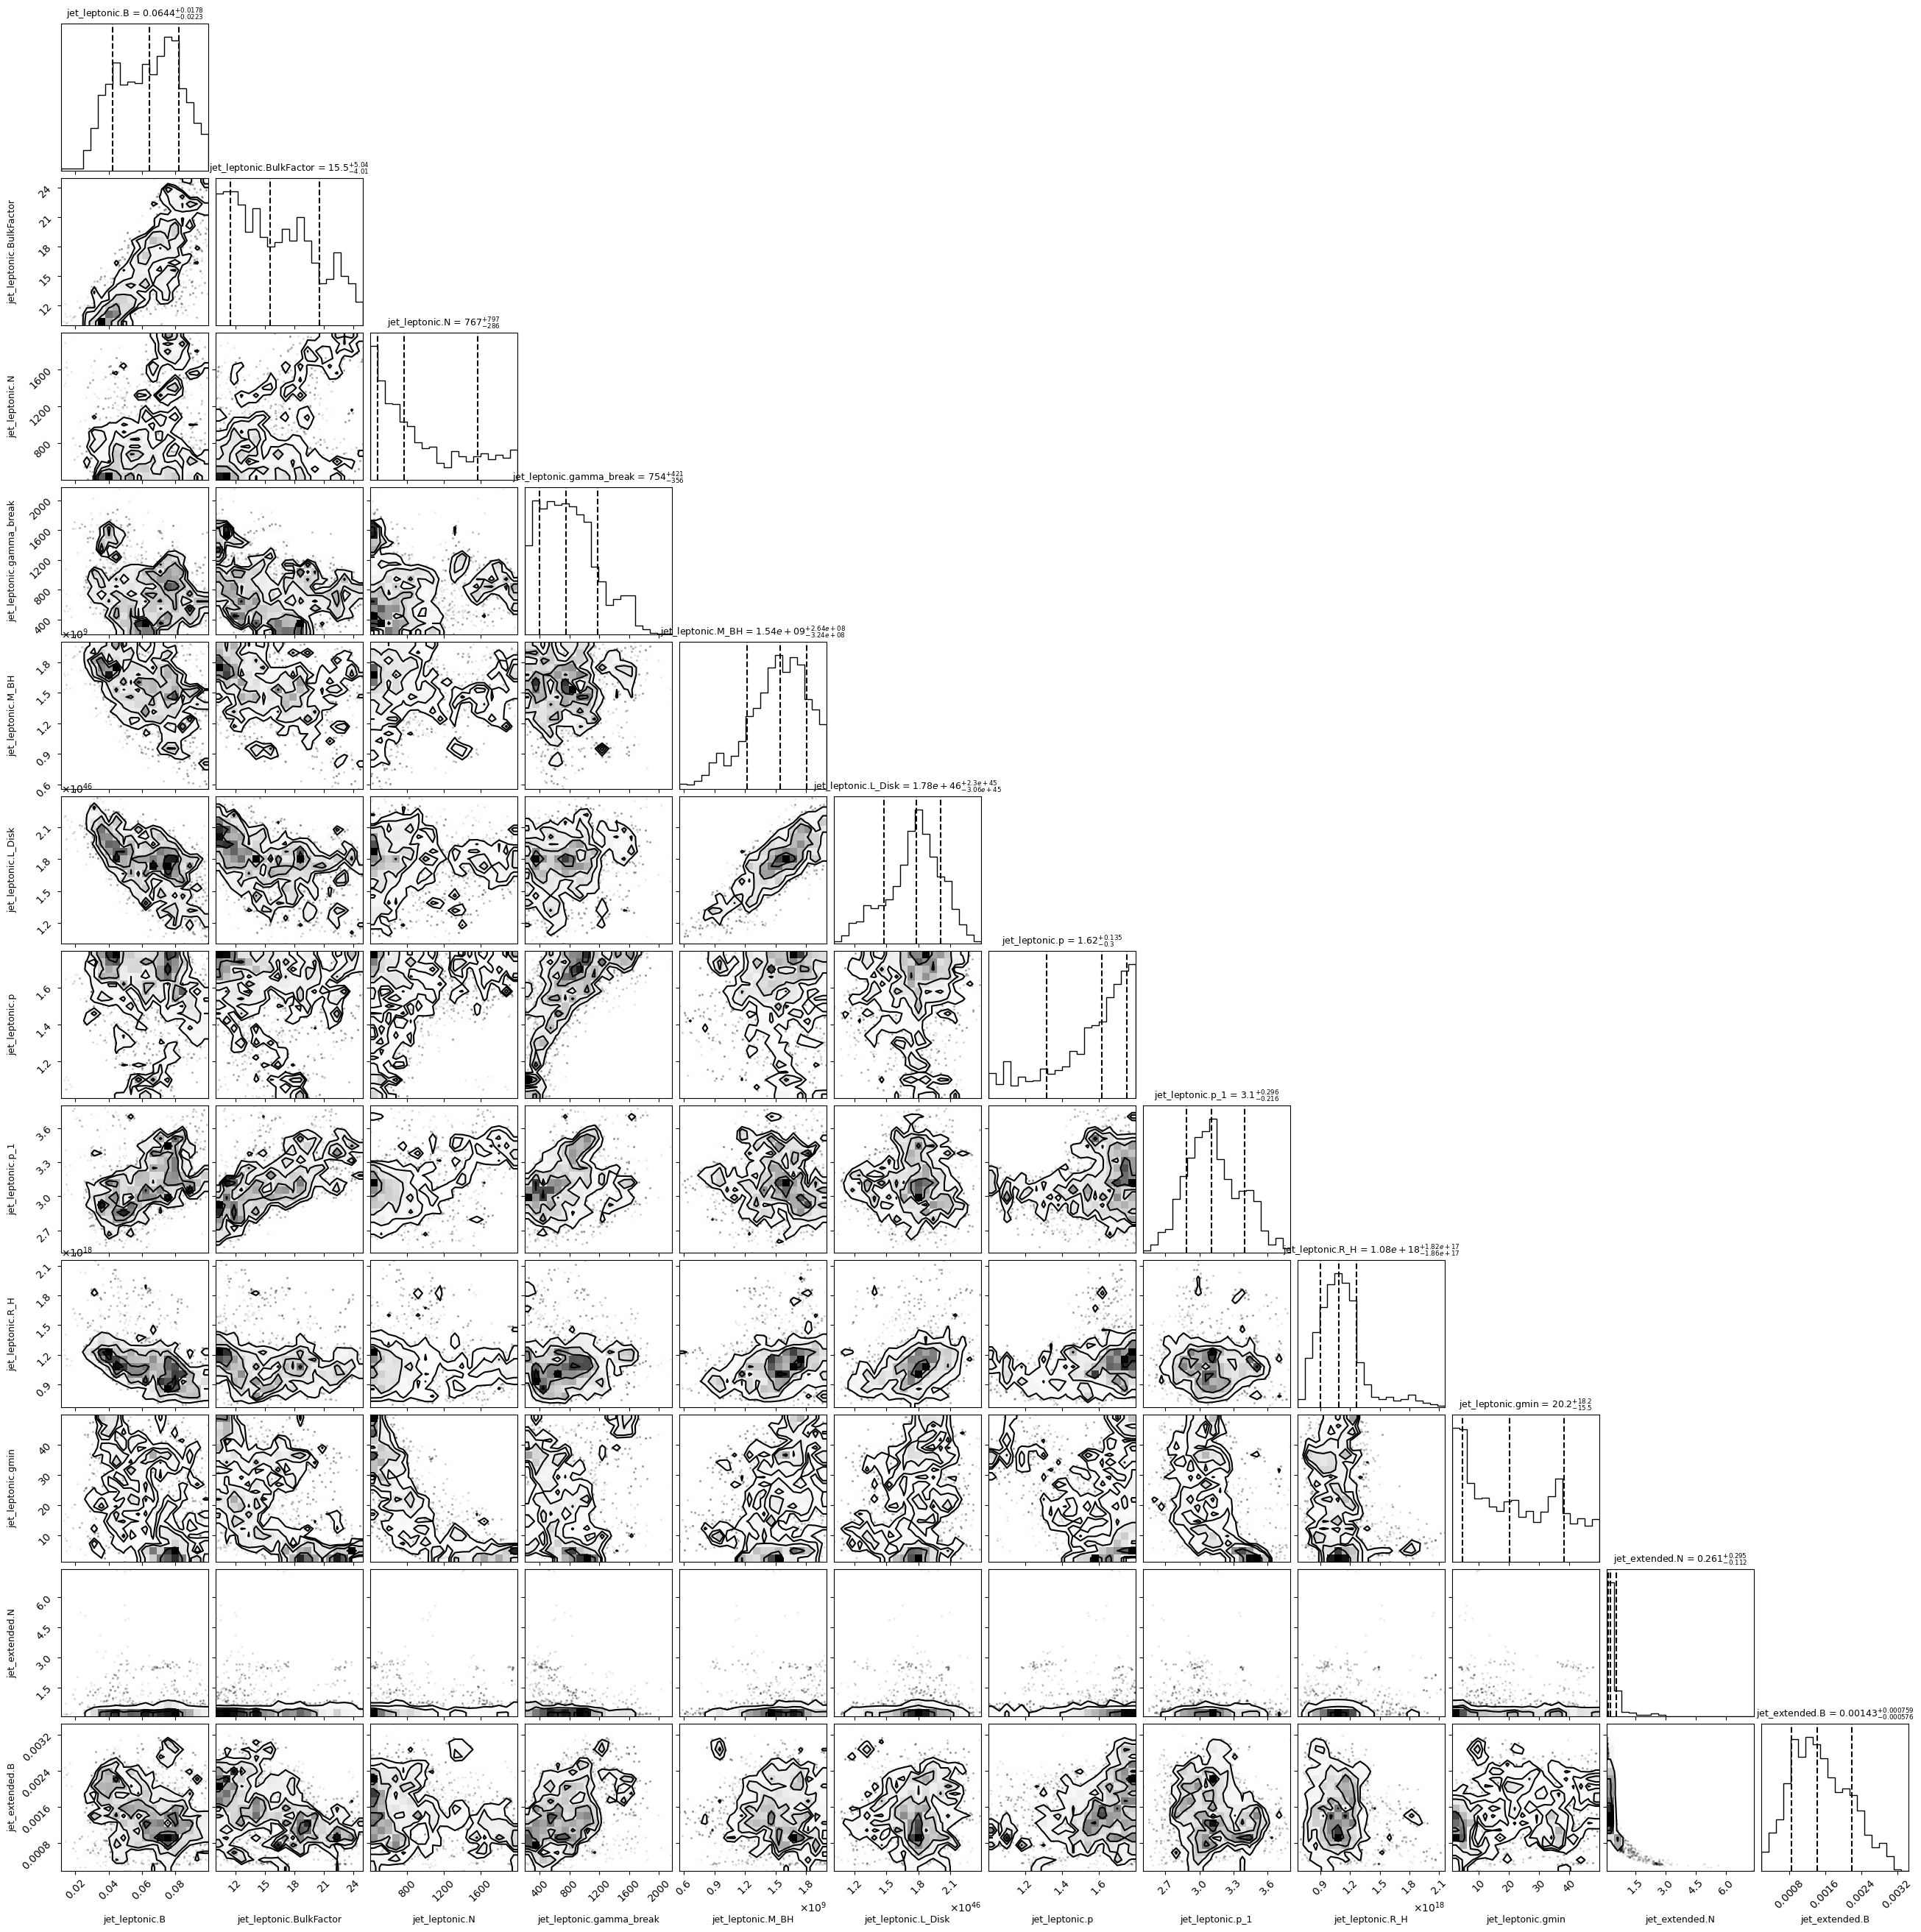

>>> Checkpoint 5.3: Corner plot saved -> ultranest_corner.png

>>> Checkpoint 5.4: Posterior median parameter values
    jet_leptonic.B = 6.4404e-02
    jet_leptonic.BulkFactor = 1.5523e+01
    jet_leptonic.N = 7.6720e+02
    jet_leptonic.gamma_break = 7.5357e+02
    jet_leptonic.M_BH = 1.5406e+09
    jet_leptonic.L_Disk = 1.7826e+46
    jet_leptonic.p = 1.6162e+00
    jet_leptonic.p_1 = 3.1027e+00
    jet_leptonic.R_H = 1.0828e+18
    jet_leptonic.gmin = 2.0179e+01
    jet_extended.N = 2.6137e-01
    jet_extended.B = 1.4295e-03


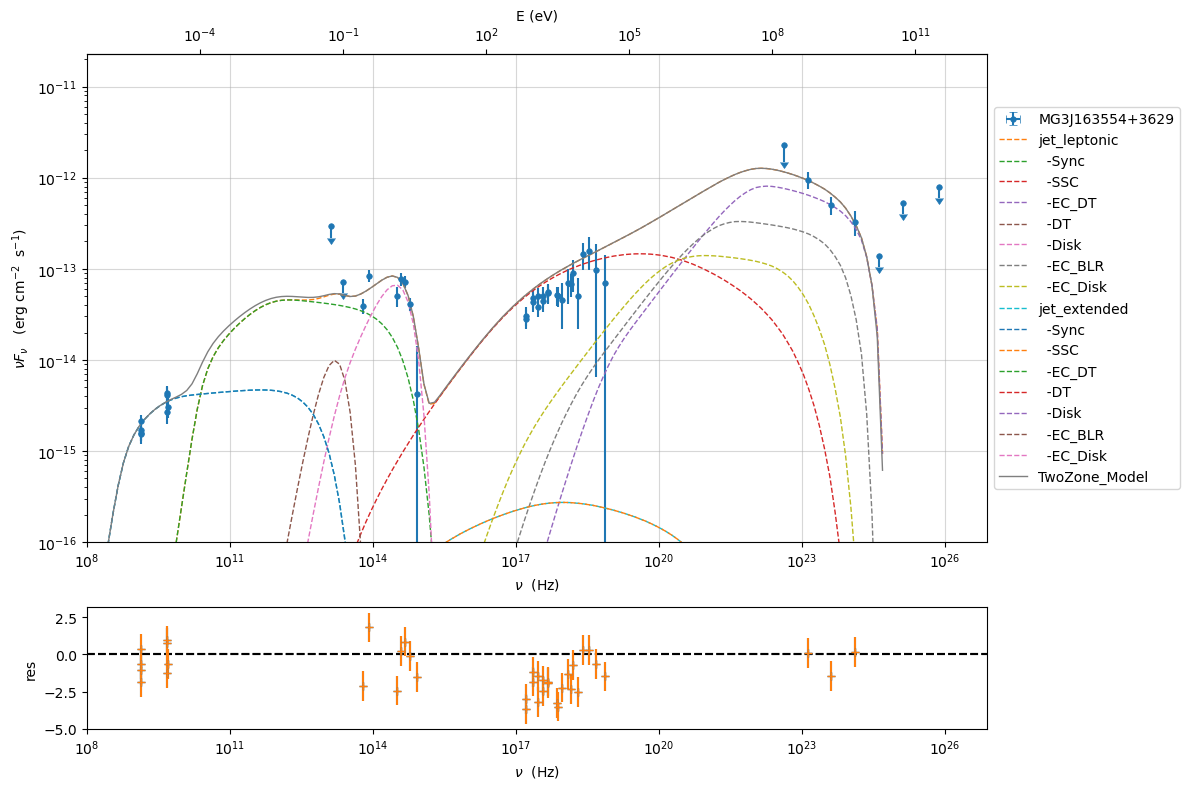

>>> Checkpoint 5.5: Best-fit (median) SED saved -> ultranest_bestfit_sed.png


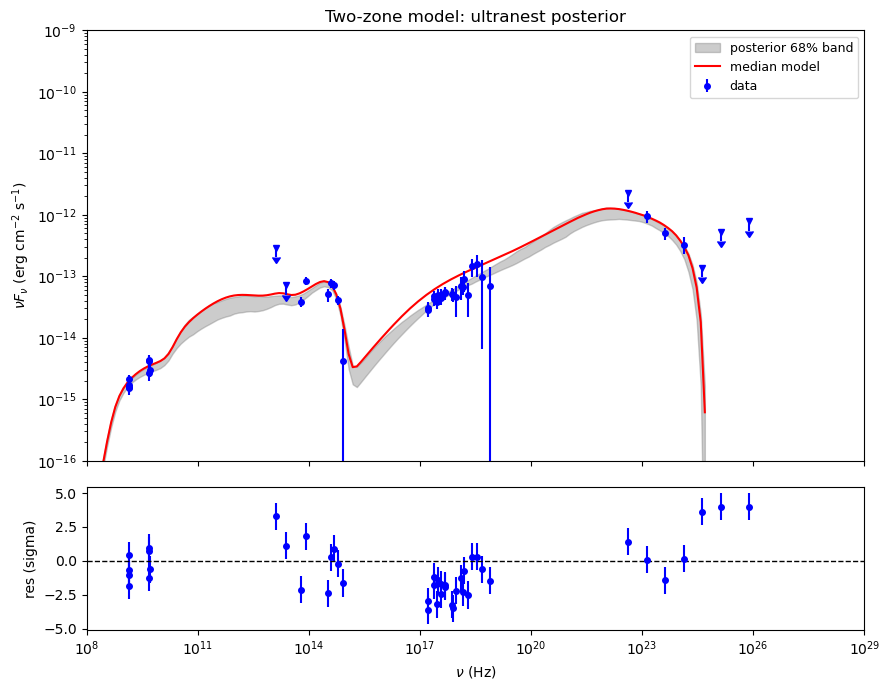

>>> Checkpoint 5.6: Posterior band SED saved -> ultranest_posterior_band_sed.png

>>> PART 5 COMPLETE.
    Saved: ultranest_corner.png, ultranest_bestfit_sed.png, ultranest_posterior_band_sed.png


In [22]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import json
import glob

from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

# 1. Reload data + model (self-contained, in case fresh kernel)
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)

fit_mask = (nu_obs >= 1e8) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

fit_model = FitModel.load_model('TwoZone_final.pkl')
fit_model.eval()

free_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'M_BH', 'L_Disk',
      'p', 'p_1', 'R_H', 'gmin']] +
    [('jet_extended', n) for n in ['N', 'B']]
)
param_labels = [f"{jet}.{name}" for jet, name in free_params]

print(">>> Checkpoint 5.1: Data and model reloaded.")

# 2. Load ultranest posterior samples
chain_files = sorted(glob.glob('ultranest_TwoZone_radio/chains/equal_weighted_post.txt'))
if not chain_files:
    chain_files = sorted(glob.glob('ultranest_TwoZone_radio/chains/weighted_post*.txt'))

if not chain_files:
    raise FileNotFoundError(
        "Could not find ultranest chain files under "
        "ultranest_TwoZone_radio/run*/chains/. "
        "Run: import glob; print(glob.glob('ultranest_TwoZone_radio/**', recursive=True)) "
        "to locate the correct path."
    )

chain_file = chain_files[-1]
print(f">>> Checkpoint 5.2: Loading chain from {chain_file}")

# equal_weighted_post.txt has a header row with param names
samples = np.loadtxt(chain_file, skiprows=1)
print(f"    samples shape: {samples.shape}")

# 3. Corner plot
try:
    import corner
    fig = corner.corner(
        samples,
        labels=param_labels,
        quantiles=(0.16, 0.5, 0.84),
        show_titles=True,
        title_fmt=".3g",
        title_kwargs=dict(fontsize=9),
        label_kwargs=dict(fontsize=9),
        use_math_text=True
    )
    plt.savefig('ultranest_corner.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(">>> Checkpoint 5.3: Corner plot saved -> ultranest_corner.png")
except ImportError:
    print("corner package not installed -- skipping corner plot")

# 4. Best-fit SED: set model to posterior MEDIAN, plot vs data
median_vals = np.median(samples, axis=0)

print("\n>>> Checkpoint 5.4: Posterior median parameter values")
for (jet, name), val in zip(free_params, median_vals):
    getattr(fit_model, jet).set_par(name, val=val)
    print(f"    {jet}.{name} = {val:.4e}")

fit_model.eval()

p = fit_model.plot_model(sed_data=sed_data)
p.add_residual_plot(fit_model, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
p.save('ultranest_bestfit_sed.png')
plt.show()

print(">>> Checkpoint 5.5: Best-fit (median) SED saved -> ultranest_bestfit_sed.png")

# 5. SED with posterior uncertainty band (random draws)
n_draws = 100
rng = np.random.default_rng(42)
draw_idx = rng.choice(len(samples), size=min(n_draws, len(samples)), replace=False)

nu_plot = fit_model.SED.nu.value
flux_draws = []

for idx in draw_idx:
    for (jet, name), val in zip(free_params, samples[idx]):
        getattr(fit_model, jet).set_par(name, val=val)
    fit_model.eval()
    flux_draws.append(fit_model.SED.nuFnu.value)

flux_draws = np.array(flux_draws)
flux_lo = np.percentile(flux_draws, 16, axis=0)
flux_hi = np.percentile(flux_draws, 84, axis=0)

# Restore median for the central line
for (jet, name), val in zip(free_params, median_vals):
    getattr(fit_model, jet).set_par(name, val=val)
fit_model.eval()
flux_median = fit_model.SED.nuFnu.value

fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

good = (nu_plot > 0) & (flux_median > 0)
ax.fill_between(nu_plot[good], flux_lo[good], flux_hi[good],
                color='gray', alpha=0.4, label='posterior 68% band')
ax.plot(nu_plot[good], flux_median[good], 'r-', lw=1.5, label='median model')

ul = is_ul
ax.errorbar(nu_obs[~ul], flux_obs[~ul], yerr=flux_err[~ul], fmt='o',
             color='blue', ms=4, label='data')
ax.errorbar(nu_obs[ul], flux_obs[ul], yerr=flux_obs[ul]*0.3, fmt='v',
             color='blue', ms=4, uplims=True)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-16, 1e-9)
ax.set_xlim(1e8, 1e29)
ax.set_ylabel(r'$\nu F_\nu$ (erg cm$^{-2}$ s$^{-1}$)')
ax.legend(fontsize=9)
ax.set_title('Two-zone model: ultranest posterior')

# Residuals (median model)
model_at_data = np.interp(nu_obs, nu_plot[good], flux_median[good])
res = (flux_obs - model_at_data) / flux_err
axr.errorbar(nu_obs, res, yerr=1.0, fmt='o', color='blue', ms=4)
axr.axhline(0, color='k', ls='--', lw=1)
axr.set_xscale('log')
axr.set_xlabel(r'$\nu$ (Hz)')
axr.set_ylabel('res (sigma)')

plt.tight_layout()
plt.savefig('ultranest_posterior_band_sed.png', dpi=150, bbox_inches='tight')
plt.show()

print(">>> Checkpoint 5.6: Posterior band SED saved -> ultranest_posterior_band_sed.png")

print("\n>>> PART 5 COMPLETE.")
print("    Saved: ultranest_corner.png, ultranest_bestfit_sed.png, "
      "ultranest_posterior_band_sed.png")

In [21]:
import glob
print(glob.glob('ultranest_TwoZone_radio/**', recursive=True))

['ultranest_TwoZone_radio/', 'ultranest_TwoZone_radio/plots', 'ultranest_TwoZone_radio/extra', 'ultranest_TwoZone_radio/info', 'ultranest_TwoZone_radio/info/results.json', 'ultranest_TwoZone_radio/info/post_summary.csv', 'ultranest_TwoZone_radio/results', 'ultranest_TwoZone_radio/results/points.hdf5', 'ultranest_TwoZone_radio/debug.log', 'ultranest_TwoZone_radio/chains', 'ultranest_TwoZone_radio/chains/equal_weighted_post.txt', 'ultranest_TwoZone_radio/chains/weighted_post.txt', 'ultranest_TwoZone_radio/chains/weighted_post_untransformed.txt', 'ultranest_TwoZone_radio/chains/run.txt']


## Compare Minuit best-fit vs ultranest posterior median

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
ad

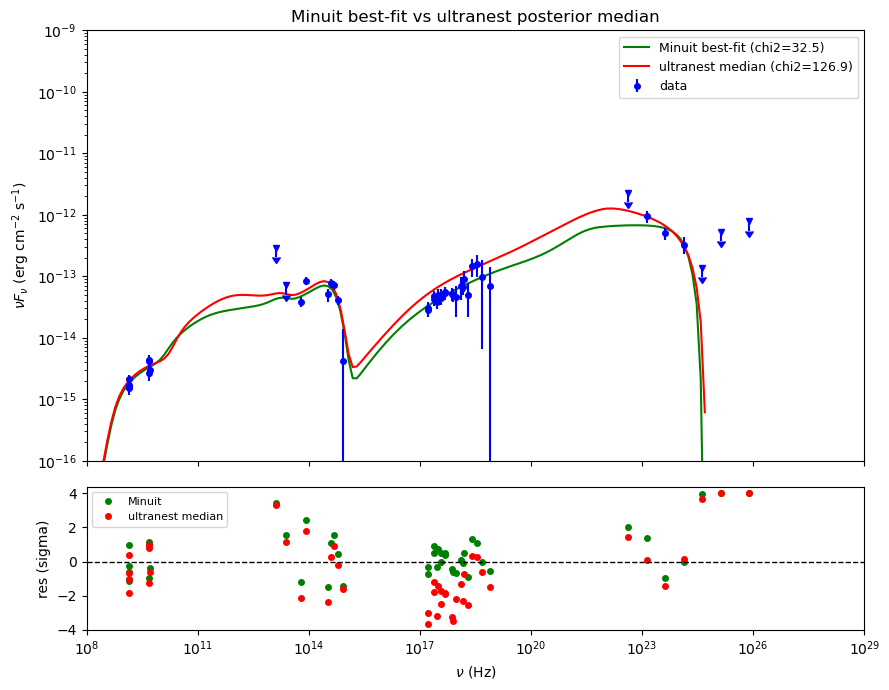


>>> PART 6 COMPLETE.
    Saved: minuit_vs_ultranest_comparison.png


In [23]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

# 1. Reload data
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)

fit_mask = (nu_obs >= 1e8) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

# 2. Minuit best-fit (fresh load, untouched)
model_minuit = FitModel.load_model('TwoZone_final.pkl')
model_minuit.eval()

nu_minuit = np.array(model_minuit.SED.nu)
flux_minuit = np.array(model_minuit.SED.nuFnu)

print(">>> Checkpoint 6.1: Minuit best-fit model loaded.")
print(f"    jet_leptonic.M_BH = {model_minuit.jet_leptonic.parameters.M_BH.val:.4e}")
print(f"    jet_leptonic.L_Disk = {model_minuit.jet_leptonic.parameters.L_Disk.val:.4e}")
print(f"    jet_leptonic.BulkFactor = {model_minuit.jet_leptonic.parameters.BulkFactor.val:.4e}")

# 3. ultranest posterior median (fresh load, apply median)
model_un = FitModel.load_model('TwoZone_final.pkl')

free_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'M_BH', 'L_Disk',
      'p', 'p_1', 'R_H', 'gmin']] +
    [('jet_extended', n) for n in ['N', 'B']]
)

samples = np.loadtxt('ultranest_TwoZone_radio/chains/equal_weighted_post.txt', skiprows=1)
median_vals = np.median(samples, axis=0)

print("\n>>> Checkpoint 6.2: ultranest posterior median values")
for (jet, name), val in zip(free_params, median_vals):
    getattr(model_un, jet).set_par(name, val=val)
    print(f"    {jet}.{name} = {val:.4e}  "
          f"(Minuit: {getattr(model_minuit, jet).parameters.get_par_by_name(name).val:.4e})")

model_un.eval()
nu_un = np.array(model_un.SED.nu)
flux_un = np.array(model_un.SED.nuFnu)

# 4. Compute chi2 for each model against the 45-point data
def chi2_of(nu_grid, flux_grid):
    good = (flux_grid > 0) & np.isfinite(flux_grid) & (nu_grid > 0)
    idx = np.argsort(nu_grid[good])
    model_at_data = np.interp(nu_obs, nu_grid[good][idx], flux_grid[good][idx],
                               left=0., right=0.)
    chi2 = 0.0
    for i in range(len(nu_obs)):
        if flux_err[i] <= 0:
            continue
        if is_ul[i]:
            if model_at_data[i] > flux_obs[i]:
                chi2 += ((model_at_data[i] - flux_obs[i]) / flux_err[i])**2
        else:
            chi2 += ((model_at_data[i] - flux_obs[i]) / flux_err[i])**2
    return chi2, model_at_data

chi2_minuit, model_at_data_minuit = chi2_of(nu_minuit, flux_minuit)
chi2_un, model_at_data_un = chi2_of(nu_un, flux_un)

print(f"\n>>> Checkpoint 6.3: chi2 comparison (45 points)")
print(f"    Minuit best-fit   : chi2 = {chi2_minuit:.3f}")
print(f"    ultranest median  : chi2 = {chi2_un:.3f}")

# 5. Plot both on same axes
fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

good_m = (flux_minuit > 0)
good_u = (flux_un > 0)
ax.plot(nu_minuit[good_m], flux_minuit[good_m], '-', color='green', lw=1.5,
        label=f'Minuit best-fit (chi2={chi2_minuit:.1f})')
ax.plot(nu_un[good_u], flux_un[good_u], '-', color='red', lw=1.5,
        label=f'ultranest median (chi2={chi2_un:.1f})')

ax.errorbar(nu_obs[~is_ul], flux_obs[~is_ul], yerr=flux_err[~is_ul], fmt='o',
             color='blue', ms=4, label='data')
ax.errorbar(nu_obs[is_ul], flux_obs[is_ul], yerr=flux_obs[is_ul]*0.3, fmt='v',
             color='blue', ms=4, uplims=True)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-16, 1e-9)
ax.set_xlim(1e8, 1e29)
ax.set_ylabel(r'$\nu F_\nu$ (erg cm$^{-2}$ s$^{-1}$)')
ax.legend(fontsize=9)
ax.set_title('Minuit best-fit vs ultranest posterior median')

# Residuals for both
res_minuit = (flux_obs - model_at_data_minuit) / flux_err
res_un = (flux_obs - model_at_data_un) / flux_err

axr.plot(nu_obs, res_minuit, 'o', color='green', ms=4, label='Minuit')
axr.plot(nu_obs, res_un, 'o', color='red', ms=4, label='ultranest median')
axr.axhline(0, color='k', ls='--', lw=1)
axr.set_xscale('log')
axr.set_xlabel(r'$\nu$ (Hz)')
axr.set_ylabel('res (sigma)')
axr.legend(fontsize=8)

plt.tight_layout()
plt.savefig('minuit_vs_ultranest_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n>>> PART 6 COMPLETE.")
print("    Saved: minuit_vs_ultranest_comparison.png")

## Reduced ultranest run (7 free params)
Frozen at Minuit best-fit values (TwoZone_final.pkl): p, p_1, M_BH, L_Disk, gmin, jet_extended.B, T_DT Free: jet_leptonic: B, BulkFactor, N, gamma_break, R_H, accr_eff jet_extended: N Same fit_mask (1e8-1e29 Hz, includes radio points), same 45-point sed_data as Part 4.

In [24]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import ultranest
import ultranest.stepsampler
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

# 1. LOAD DATA
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)

fit_mask = (nu_obs >= 1e8) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

# Exclude the last 2 (highest-frequency) Fermi/gamma-ray points,
# per request -- these were driving an overprediction at the
# high-energy end in the 12-param ultranest run.
order = np.argsort(nu_obs)
nu_obs_sorted = nu_obs[order]
top2_nu = nu_obs_sorted[-2:]
exclude_mask = ~np.isin(nu_obs, top2_nu)

print(f">>> Excluding top-2 highest-frequency points: {top2_nu}")

nu_obs   = nu_obs[exclude_mask]
flux_obs = flux_obs[exclude_mask]
flux_err = flux_err[exclude_mask]
is_ul    = is_ul[exclude_mask]

print(">>> Checkpoint U4b.1: Data loaded (top-2 Fermi points excluded)")
print(f"    N points in fit: {len(nu_obs)}")

# 2. LOAD TWO-ZONE BEST-FIT MODEL, FREEZE ALL
fit_model = FitModel.load_model('TwoZone_final.pkl')
fit_model.eval()

for par in fit_model.jet_leptonic.parameters.par_array:
    par.frozen = True
for par in fit_model.jet_extended.parameters.par_array:
    par.frozen = True

# Free parameters: 7 total
#   jet_leptonic: B, BulkFactor, N, gamma_break, R_H, accr_eff
#   jet_extended: N
# p, p_1, M_BH, L_Disk, gmin, jet_extended.B, T_DT all stay
# FROZEN at their Minuit best-fit values (already set from
# TwoZone_final.pkl).
free_params_zone1 = ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']
free_params_zone2 = ['N']

for name in free_params_zone1:
    fit_model.jet_leptonic.parameters.get_par_by_name(name).frozen = False
for name in free_params_zone2:
    fit_model.jet_extended.parameters.get_par_by_name(name).frozen = False

free_params = (
    [('jet_leptonic', n) for n in free_params_zone1] +
    [('jet_extended', n) for n in free_params_zone2]
)
param_labels = [f"{jet}.{name}" for jet, name in free_params]

print(">>> Checkpoint U4b.2: Free parameters (7 total)")
print("    Frozen at Minuit values: p, p_1, M_BH, L_Disk, gmin, "
      "jet_extended.B, T_DT")
for jet, name in free_params:
    print(f"    FREE {jet}.{name} = "
          f"{getattr(fit_model, jet).parameters.get_par_by_name(name).val:.4e}")

print(f"\n    Frozen values (for reference):")
print(f"    jet_leptonic.p       = {fit_model.jet_leptonic.parameters.p.val:.4f}")
print(f"    jet_leptonic.p_1     = {fit_model.jet_leptonic.parameters.p_1.val:.4f}")
print(f"    jet_leptonic.M_BH    = {fit_model.jet_leptonic.parameters.M_BH.val:.4e}")
print(f"    jet_leptonic.L_Disk  = {fit_model.jet_leptonic.parameters.L_Disk.val:.4e}")
print(f"    jet_leptonic.gmin    = {fit_model.jet_leptonic.parameters.gmin.val:.4f}")
print(f"    jet_leptonic.T_DT    = {fit_model.jet_leptonic.parameters.T_DT.val:.4f}")
print(f"    jet_extended.B       = {fit_model.jet_extended.parameters.B.val:.4e}")

# Prior ranges: centered on Minuit best-fit, physically
# motivated widths (same bounds used as fit_range in Part 3,
# plus accr_eff's physical bound [0.06, 0.10])
prior_mins = np.array([
    0.010,    # jet_leptonic.B
    10.0,     # jet_leptonic.BulkFactor
    400.0,    # jet_leptonic.N
    200.0,    # jet_leptonic.gamma_break
    5.0e17,   # jet_leptonic.R_H
    0.060,    # jet_leptonic.accr_eff
    1.0e-3,   # jet_extended.N
])
prior_maxs = np.array([
    0.100,    # jet_leptonic.B
    25.0,     # jet_leptonic.BulkFactor
    2000.0,   # jet_leptonic.N
    3000.0,   # jet_leptonic.gamma_break
    3.0e18,   # jet_leptonic.R_H
    0.100,    # jet_leptonic.accr_eff
    10.0,     # jet_extended.N
])

assert len(prior_mins) == len(free_params)
assert len(prior_maxs) == len(free_params)

def prior_transform(cube):
    return prior_mins + cube * (prior_maxs - prior_mins)

def get_composite_flux(nu_target):
    fit_model.eval()
    nu_grid   = fit_model.SED.nu.value
    flux_grid = fit_model.SED.nuFnu.value
    good      = np.isfinite(flux_grid) & np.isfinite(nu_grid) & (nu_grid > 0)
    nu_g      = nu_grid[good]
    fl_g      = flux_grid[good]
    idx       = np.argsort(nu_g)
    return np.interp(nu_target, nu_g[idx], fl_g[idx], left=0., right=0.)

def log_likelihood(params):
    try:
        for (jet_name, par_name), val in zip(free_params, params):
            getattr(fit_model, jet_name).set_par(par_name, val=val)
        model_flux = get_composite_flux(nu_obs)
        if np.any(~np.isfinite(model_flux)):
            return -1e100
        chi2 = 0.0
        for i in range(len(nu_obs)):
            if flux_err[i] <= 0:
                continue
            if is_ul[i]:
                if model_flux[i] > flux_obs[i]:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            else:
                if model_flux[i] > 0:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
        return -0.5 * chi2 if np.isfinite(chi2) else -1e100
    except Exception:
        return -1e100

# Sanity check at starting point
best_vals = np.array([
    getattr(fit_model, jet).parameters.get_par_by_name(name).val
    for jet, name in free_params
])
ll_test = log_likelihood(best_vals)
print(f"\n>>> Checkpoint U4b.3: Log-likelihood at starting point: {ll_test:.4f}")

# 3. RUN ULTRANEST
sampler = ultranest.ReactiveNestedSampler(
    param_names = param_labels,
    loglike     = log_likelihood,
    transform   = prior_transform,
    log_dir     = 'ultranest_TwoZone_radio_reduced',
    resume      = 'resume'
)
sampler.stepsampler = ultranest.stepsampler.SliceSampler(
    nsteps             = 2 * len(free_params),
    generate_direction = ultranest.stepsampler.generate_mixture_random_direction
)

results = sampler.run(
    min_num_live_points = 200,
    max_iters           = 100000,
    show_status         = True,
    viz_callback        = False
)

sampler.print_results()
print(f"\nlogZ = {results['logz']:.3f} +/- {results['logzerr']:.3f}")

print("\n>>> PART 4b COMPLETE.")
print("    ultranest output saved in: ultranest_TwoZone_radio_reduced/")
print("    Compare logZ with Part 4's 12-param run (logZ=-36.645+-0.395)")
print("    to see if the simpler model is preferred (higher logZ = better).")

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
>>> Excluding top-2 highest-frequency points: [1.324e+25 7.646e+25]
>>> Checkpoint U4b.1: Data loaded (top-2 Fermi points excluded)
    N points in fit: 43
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] 

## Compare Minuit best-fit vs ultranest posterior median

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
ad

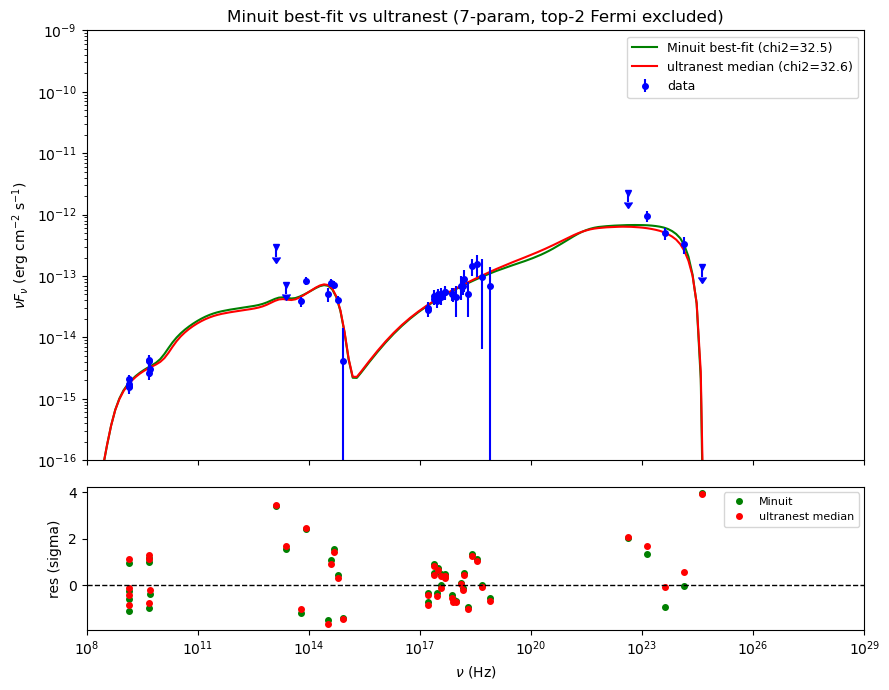


>>> PART 6 COMPLETE.
    Saved: minuit_vs_ultranest_comparison.png


In [25]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

# 1. Reload data
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)

fit_mask = (nu_obs >= 1e8) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

# Exclude top-2 highest-frequency Fermi points (as in Part 4b)
order = np.argsort(nu_obs)
top2_nu = nu_obs[order][-2:]
exclude_mask = ~np.isin(nu_obs, top2_nu)
nu_obs   = nu_obs[exclude_mask]
flux_obs = flux_obs[exclude_mask]
flux_err = flux_err[exclude_mask]
is_ul    = is_ul[exclude_mask]

# 2. Minuit best-fit (fresh load, untouched)
model_minuit = FitModel.load_model('TwoZone_final.pkl')
model_minuit.eval()

nu_minuit = np.array(model_minuit.SED.nu)
flux_minuit = np.array(model_minuit.SED.nuFnu)

print(">>> Checkpoint 6.1: Minuit best-fit model loaded.")
print(f"    jet_leptonic.M_BH = {model_minuit.jet_leptonic.parameters.M_BH.val:.4e}")
print(f"    jet_leptonic.L_Disk = {model_minuit.jet_leptonic.parameters.L_Disk.val:.4e}")
print(f"    jet_leptonic.BulkFactor = {model_minuit.jet_leptonic.parameters.BulkFactor.val:.4e}")

# 3. ultranest posterior median (fresh load, apply median)
model_un = FitModel.load_model('TwoZone_final.pkl')

free_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']] +
    [('jet_extended', n) for n in ['N']]
)

samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt', skiprows=1)
median_vals = np.median(samples, axis=0)

print("\n>>> Checkpoint 6.2: ultranest posterior median values")
for (jet, name), val in zip(free_params, median_vals):
    getattr(model_un, jet).set_par(name, val=val)
    print(f"    {jet}.{name} = {val:.4e}  "
          f"(Minuit: {getattr(model_minuit, jet).parameters.get_par_by_name(name).val:.4e})")

model_un.eval()
nu_un = np.array(model_un.SED.nu)
flux_un = np.array(model_un.SED.nuFnu)

# 4. Compute chi2 for each model against the 45-point data
def chi2_of(nu_grid, flux_grid):
    good = (flux_grid > 0) & np.isfinite(flux_grid) & (nu_grid > 0)
    idx = np.argsort(nu_grid[good])
    model_at_data = np.interp(nu_obs, nu_grid[good][idx], flux_grid[good][idx],
                               left=0., right=0.)
    chi2 = 0.0
    for i in range(len(nu_obs)):
        if flux_err[i] <= 0:
            continue
        if is_ul[i]:
            if model_at_data[i] > flux_obs[i]:
                chi2 += ((model_at_data[i] - flux_obs[i]) / flux_err[i])**2
        else:
            chi2 += ((model_at_data[i] - flux_obs[i]) / flux_err[i])**2
    return chi2, model_at_data

chi2_minuit, model_at_data_minuit = chi2_of(nu_minuit, flux_minuit)
chi2_un, model_at_data_un = chi2_of(nu_un, flux_un)

print(f"\n>>> Checkpoint 6.3: chi2 comparison (45 points)")
print(f"    Minuit best-fit   : chi2 = {chi2_minuit:.3f}")
print(f"    ultranest median  : chi2 = {chi2_un:.3f}")

# 5. Plot both on same axes
fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

good_m = (flux_minuit > 0)
good_u = (flux_un > 0)
ax.plot(nu_minuit[good_m], flux_minuit[good_m], '-', color='green', lw=1.5,
        label=f'Minuit best-fit (chi2={chi2_minuit:.1f})')
ax.plot(nu_un[good_u], flux_un[good_u], '-', color='red', lw=1.5,
        label=f'ultranest median (chi2={chi2_un:.1f})')

ax.errorbar(nu_obs[~is_ul], flux_obs[~is_ul], yerr=flux_err[~is_ul], fmt='o',
             color='blue', ms=4, label='data')
ax.errorbar(nu_obs[is_ul], flux_obs[is_ul], yerr=flux_obs[is_ul]*0.3, fmt='v',
             color='blue', ms=4, uplims=True)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-16, 1e-9)
ax.set_xlim(1e8, 1e29)
ax.set_ylabel(r'$\nu F_\nu$ (erg cm$^{-2}$ s$^{-1}$)')
ax.legend(fontsize=9)
ax.set_title('Minuit best-fit vs ultranest (7-param, top-2 Fermi excluded)')

# Residuals for both
res_minuit = (flux_obs - model_at_data_minuit) / flux_err
res_un = (flux_obs - model_at_data_un) / flux_err

axr.plot(nu_obs, res_minuit, 'o', color='green', ms=4, label='Minuit')
axr.plot(nu_obs, res_un, 'o', color='red', ms=4, label='ultranest median')
axr.axhline(0, color='k', ls='--', lw=1)
axr.set_xscale('log')
axr.set_xlabel(r'$\nu$ (Hz)')
axr.set_ylabel('res (sigma)')
axr.legend(fontsize=8)

plt.tight_layout()
plt.savefig('minuit_vs_ultranest_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n>>> PART 6 COMPLETE.")
print("    Saved: minuit_vs_ultranest_comparison.png")

## Final parameter values - Minuit best-fit and
ultranest posterior summary (median, 16th/84th pct)

In [26]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
from jetset.model_manager import FitModel

# 1. Minuit best-fit values
model_minuit = FitModel.load_model('TwoZone_final.pkl')
model_minuit.eval()

# All free params from Part 4b's 7-param run + the frozen ones
all_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff',
      'p', 'p_1', 'M_BH', 'L_Disk', 'gmin', 'T_DT']] +
    [('jet_extended', n) for n in ['N', 'B']]
)

free_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']] +
    [('jet_extended', n) for n in ['N']]
)

print(">>> Checkpoint 7.1: Minuit best-fit values (all relevant params)")
print(f"{'Param':<28} {'Minuit':>14}")
print("-" * 44)
minuit_vals = {}
for jet, name in all_params:
    val = getattr(model_minuit, jet).parameters.get_par_by_name(name).val
    minuit_vals[(jet, name)] = val
    print(f"{jet}.{name:<20} {val:>14.4e}")

# 2. ultranest posterior summary (7 free params)
samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                      skiprows=1)

median_vals = np.median(samples, axis=0)
p16 = np.percentile(samples, 16, axis=0)
p84 = np.percentile(samples, 84, axis=0)

print("\n>>> Checkpoint 7.2: ultranest posterior summary (7 free params)")
print(f"{'Param':<28} {'Median':>12} {'-1sigma':>12} {'+1sigma':>12} "
      f"{'Minuit':>12}")
print("-" * 80)
for i, (jet, name) in enumerate(free_params):
    med = median_vals[i]
    lo = med - p16[i]
    hi = p84[i] - med
    mv = minuit_vals[(jet, name)]
    print(f"{jet}.{name:<20} {med:>12.4e} {lo:>12.4e} {hi:>12.4e} {mv:>12.4e}")

# 3. Frozen params (same for both, for completeness)
frozen_params = [p for p in all_params if p not in free_params]

print("\n>>> Checkpoint 7.3: Frozen parameters (fixed at Minuit values)")
for jet, name in frozen_params:
    print(f"    {jet}.{name:<20} = {minuit_vals[(jet, name)]:.4e}")

# 4. Derived quantities at the ultranest median
for (jet, name), val in zip(free_params, median_vals):
    getattr(model_minuit, jet).set_par(name, val=val)
model_minuit.eval()

print("\n>>> Checkpoint 7.4: Derived quantities (at ultranest median)")
print(f"    Beaming factor (Zone 1) = {model_minuit.jet_leptonic.get_beaming():.4f}")
print(f"    Beaming factor (Zone 2) = {model_minuit.jet_extended.get_beaming():.4f}")
print(f"    R (Zone 1)  = {model_minuit.jet_leptonic.parameters.R.val:.4e} cm")
print(f"    R (Zone 2)  = {model_minuit.jet_extended.parameters.R.val:.4e} cm")
print(f"    R_DT        = {model_minuit.jet_leptonic.parameters.R_DT.val:.4e} cm")
print(f"    R_BLR_in    = {model_minuit.jet_leptonic.parameters.R_BLR_in.val:.4e} cm")

# 5. Save summary table to file
with open('final_parameters_summary.txt', 'w') as f:
    f.write("FINAL PARAMETER VALUES - Two-Zone Leptonic SSC+EC Model\n")
    f.write("MG3 J163554+3629\n")
    f.write("="*80 + "\n\n")

    f.write("FREE PARAMETERS (ultranest, 7-param, 43 points, top-2 Fermi excluded)\n")
    f.write("-"*80 + "\n")
    f.write(f"{'Param':<28} {'Median':>12} {'-1sigma':>12} {'+1sigma':>12} "
            f"{'Minuit':>12}\n")
    for i, (jet, name) in enumerate(free_params):
        med = median_vals[i]
        lo = med - p16[i]
        hi = p84[i] - med
        mv = minuit_vals[(jet, name)]
        f.write(f"{jet}.{name:<20} {med:>12.4e} {lo:>12.4e} {hi:>12.4e} {mv:>12.4e}\n")

    f.write("\nFROZEN PARAMETERS (fixed at Minuit best-fit)\n")
    f.write("-"*80 + "\n")
    for jet, name in frozen_params:
        f.write(f"{jet}.{name:<20} = {minuit_vals[(jet, name)]:.4e}\n")

    f.write("\nDERIVED QUANTITIES (at ultranest median)\n")
    f.write("-"*80 + "\n")
    f.write(f"Beaming factor (Zone 1) = {model_minuit.jet_leptonic.get_beaming():.4f}\n")
    f.write(f"Beaming factor (Zone 2) = {model_minuit.jet_extended.get_beaming():.4f}\n")
    f.write(f"R (Zone 1)  = {model_minuit.jet_leptonic.parameters.R.val:.4e} cm\n")
    f.write(f"R (Zone 2)  = {model_minuit.jet_extended.parameters.R.val:.4e} cm\n")
    f.write(f"R_DT        = {model_minuit.jet_leptonic.parameters.R_DT.val:.4e} cm\n")
    f.write(f"R_BLR_in    = {model_minuit.jet_leptonic.parameters.R_BLR_in.val:.4e} cm\n")

print("\n>>> PART 7 COMPLETE.")
print("    Saved: final_parameters_summary.txt")

===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
adding par: R_ext_Sw to  R_ext_Sw
adding par: accr_eff to  accr_eff
adding par: M_BH to  M_BH
adding par: tau_BLR to  tau_BLR
adding par: L_Disk to  L_D

## MCMC with the SAME 7 free params as ultranest
(Part 4b), for direct comparison: Minuit vs MCMC vs ultranest Free params: jet_leptonic: B, BulkFactor, N, gamma_break, R_H, accr_eff jet_extended: N Data: 43 points (top-2 Fermi excluded, radio points included) NOTE: jetset's McmcSampler wraps a ModelMinimizer and samples around its best-fit. We therefore: 1. Re-run Minuit with EXACTLY these 7 free params + the 43-point dataset (frozen: p, p_1, M_BH, L_Disk, gmin, jet_extended.B, T_DT -- same as Part 4b) 2. Run McmcSampler on that minimizer

In [27]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel
from jetset.minimizer import ModelMinimizer, Minimizer
from jetset.mcmc import McmcSampler

# Re-apply safe-corr patch
def _safe_corr(self):
    if self.covar is None:
        return None
    cov = np.asarray(self.covar)
    if cov.ndim != 2 or cov.shape[0] != cov.shape[1]:
        print(">>> WARNING: covariance matrix malformed "
              f"(shape={cov.shape}) -- skipping correlation matrix.")
        return None
    v = np.sqrt(np.diag(cov))
    outer_v = np.outer(v, v)
    correlation = cov / outer_v
    correlation[cov == 0] = 0
    return correlation

Minimizer.corr = property(_safe_corr)

# 1. Build the 43-point ObsData (top-2 Fermi excluded)
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

# Exclude top-2 highest-frequency points (1.324e25, 7.646e25 Hz)
d = d[~np.isin(d[:, 0], [1.324e25, 7.646e25])]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data_43 = ObsData(data_table=data_obj)
sed_data_43.filter_data_set('-1', exclude=True)
sed_data_43.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [4.188e24, 4.188e22, 2.417e13, 1.318e13]  # top-2 removed from this list
for freq in UL_freq:
    mask = np.isclose(sed_data_43.table['nu_data'], freq, rtol=0.05)
    sed_data_43.table['UL'][mask] = True

print(">>> Checkpoint 8.1: 43-point ObsData built (top-2 Fermi excluded)")
print(f"    N points: {len(sed_data_43.table)}")

# 2. Load composite model, set freeze/free EXACTLY as Part 4b
composite_jet = FitModel.load_model('TwoZone_final.pkl')
composite_jet.eval()

composite_jet.jet_leptonic.set_num_c_threads(8)
composite_jet.jet_extended.set_num_c_threads(8)

# Freeze everything first
for par in composite_jet.jet_leptonic.parameters.par_array:
    par.frozen = True
for par in composite_jet.jet_extended.parameters.par_array:
    par.frozen = True

# Free the same 7 params as Part 4b
free_params_zone1 = ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']
free_params_zone2 = ['N']

for name in free_params_zone1:
    composite_jet.jet_leptonic.parameters.get_par_by_name(name).frozen = False
for name in free_params_zone2:
    composite_jet.jet_extended.parameters.get_par_by_name(name).frozen = False

# Fit ranges (same as Part 4b priors)
composite_jet.jet_leptonic.parameters.B.fit_range = [0.010, 0.100]
composite_jet.jet_leptonic.parameters.BulkFactor.fit_range = [10.0, 25.0]
composite_jet.jet_leptonic.parameters.N.fit_range = [4.00e+02, 2.00e+03]
composite_jet.jet_leptonic.parameters.gamma_break.fit_range = [2.00e+02, 3.00e+03]
composite_jet.jet_leptonic.parameters.R_H.fit_range = [5.0e+17, 3.0e+18]
composite_jet.jet_leptonic.parameters.accr_eff.fit_range = [0.060, 0.100]
composite_jet.jet_extended.parameters.N.fit_range = [1.0e-03, 1.0e+01]

print(">>> Checkpoint 8.2: Freeze/free configured (7 free params, same as Part 4b)")
free_params = (
    [('jet_leptonic', n) for n in free_params_zone1] +
    [('jet_extended', n) for n in free_params_zone2]
)
for jet, name in free_params:
    print(f"    FREE {jet}.{name} = "
          f"{getattr(composite_jet, jet).parameters.get_par_by_name(name).val:.4e}")

# 3. Re-run Minuit on the 43-point dataset with these 7 params
model_minimizer = ModelMinimizer('minuit')
best_fit = model_minimizer.fit(
    composite_jet, sed_data_43,
    10**8., 10**30.0,
    fitname='TwoZone_7par_43pt',
    repeat=1,
    use_UL=True
)

composite_jet.eval()
composite_jet.save_model('TwoZone_7par_43pt.pkl')

print("\n>>> Checkpoint 8.3: Minuit re-fit (7 params, 43 points) completed.")
for jet, name in free_params:
    print(f"    {jet}.{name} = "
          f"{getattr(composite_jet, jet).parameters.get_par_by_name(name).val:.4e}")

# 4. Run MCMC (same pattern as Part 5, adapted for 7 params)
mcmc = McmcSampler(model_minimizer)

mcmc.model.jet_leptonic.set_num_c_threads(8)
mcmc.model.jet_extended.set_num_c_threads(8)
mcmc.model.jet_leptonic.set_external_field_transf('disk')

use_labels_dict = {
    'jet_leptonic': free_params_zone1,
    'jet_extended': free_params_zone2,
}
mcmc.set_labels(use_labels_dict=use_labels_dict)

print("\n>>> Checkpoint 8.4: MCMC sampler configured (7 params).")

mcmc.set_bounds(bound=5.0, bound_rel=True)

mcmc.run_sampler(
    nwalkers=64,
    burnin=20,
    steps=200,
    walker_start_bound=0.005,
    progress='notebook'
)

print(">>> Checkpoint 8.5: MCMC sampling completed.")

mcmc.save('mcmc_7par_43pt.pkl')

# 5. Three-way comparison table: Minuit vs MCMC vs ultranest
mcmc_samples = mcmc.samples  # shape: (n_samples, 7)
mcmc_median = np.median(mcmc_samples, axis=0)
mcmc_p16 = np.percentile(mcmc_samples, 16, axis=0)
mcmc_p84 = np.percentile(mcmc_samples, 84, axis=0)

un_samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                          skiprows=1)
un_median = np.median(un_samples, axis=0)
un_p16 = np.percentile(un_samples, 16, axis=0)
un_p84 = np.percentile(un_samples, 84, axis=0)

print("\n>>> Checkpoint 8.6: THREE-WAY COMPARISON (43 points, 7 free params)")
print(f"{'Param':<28} {'Minuit':>12} {'MCMC median':>14} {'MCMC -/+':>16} "
      f"{'UN median':>14} {'UN -/+':>16}")
print("-" * 100)
for i, (jet, name) in enumerate(free_params):
    mv = getattr(composite_jet, jet).parameters.get_par_by_name(name).val
    mcmc_lo = mcmc_median[i] - mcmc_p16[i]
    mcmc_hi = mcmc_p84[i] - mcmc_median[i]
    un_lo = un_median[i] - un_p16[i]
    un_hi = un_p84[i] - un_median[i]
    print(f"{jet}.{name:<20} {mv:>12.4e} {mcmc_median[i]:>14.4e} "
          f"-{mcmc_lo:.2e}/+{mcmc_hi:.2e} "
          f"{un_median[i]:>14.4e} -{un_lo:.2e}/+{un_hi:.2e}")

# 6. Save comparison to file
with open('three_way_comparison.txt', 'w') as f:
    f.write("THREE-WAY PARAMETER COMPARISON\n")
    f.write("Minuit vs MCMC vs ultranest (7 free params, 43 points)\n")
    f.write("="*100 + "\n\n")
    f.write(f"{'Param':<28} {'Minuit':>12} {'MCMC median':>14} {'MCMC -1s':>12} "
            f"{'MCMC +1s':>12} {'UN median':>14} {'UN -1s':>12} {'UN +1s':>12}\n")
    for i, (jet, name) in enumerate(free_params):
        mv = getattr(composite_jet, jet).parameters.get_par_by_name(name).val
        mcmc_lo = mcmc_median[i] - mcmc_p16[i]
        mcmc_hi = mcmc_p84[i] - mcmc_median[i]
        un_lo = un_median[i] - un_p16[i]
        un_hi = un_p84[i] - un_median[i]
        f.write(f"{jet}.{name:<20} {mv:>12.4e} {mcmc_median[i]:>14.4e} "
                f"{mcmc_lo:>12.4e} {mcmc_hi:>12.4e} "
                f"{un_median[i]:>14.4e} {un_lo:>12.4e} {un_hi:>12.4e}\n")

print("\n>>> PART 8 COMPLETE.")
print("    Saved: TwoZone_7par_43pt.pkl, mcmc_7par_43pt.pkl, "
      "three_way_comparison.txt")

---> excluding  data_set/s ['-1']
filter -1 43
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=43
>>> Checkpoint 8.1: 43-point ObsData built (top-2 Fermi excluded)
    N points: 43
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T

0it [00:00, ?it/s]

====> simplex
====> migrad
- best chisq=3.17070e+01

-------------------------------------------------------------------------
Fit report

Model: TwoZone_7par_43pt


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,1.816456e+00,1.000000e+00,1.000000e+09,False,True
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.600000e+04,1.000000e+00,1.000000e+15,False,True
jet_leptonic,N,emitters_density,1 / cm3,8.021563e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_break,turn-over-energy,lorentz-factor*,5.241313e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,p,LE_spectral_slope,,1.295881e+00,-1.000000e+01,1.000000e+01,False,True
jet_leptonic,p_1,HE_spectral_slope,,2.753627e+00,-1.000000e+01,1.000000e+01,False,True
jet_leptonic,T_DT(M),DT,K,9.251537e+02,0.000000e+00,--,False,True
jet_leptonic,"*R_DT(D,L_Disk)",DT,cm,2.598243e+19,0.000000e+00,--,False,True
jet_leptonic,tau_DT(M),DT,,1.000000e-01,0.000000e+00,1.000000e+00,False,True
jet_leptonic,R_inner_Sw(M),Disk,Sw. radii*,8.535945e+00,0.000000e+00,--,False,True



converged=True
calls=1596
mesg=


...

dof=36
chisq=31.706952, chisq/red=0.880749 null hypothesis sig=0.672961

stats without the UL
dof  UL=32
chisq=31.542903, chisq/red=0.985716 null hypothesis sig=0.489572


best fit pars


model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
jet_leptonic,gmin,1.816456e+00,--,--,--,1.816456e+00,1.000000e+00,5.000000e+01,True
jet_leptonic,gmax,1.600000e+04,--,--,--,1.600000e+04,1.000000e+00,1.000000e+15,True
jet_leptonic,N,8.021563e+02,8.021563e+02,2.575479e+02,--,7.924874e+02,4.000000e+02,2.000000e+03,False
jet_leptonic,gamma_break,5.241313e+02,5.241313e+02,1.924595e+02,--,5.125445e+02,2.000000e+02,3.000000e+03,False
jet_leptonic,p,1.295881e+00,--,--,--,1.295881e+00,1.000000e+00,1.800000e+00,True
jet_leptonic,p_1,2.753627e+00,--,--,--,2.753627e+00,2.500000e+00,3.800000e+00,True
jet_leptonic,T_DT(M),9.251537e+02,--,--,--,9.251537e+02,1.000000e+02,1.000000e+03,True
jet_leptonic,"*R_DT(D,L_Disk)",2.598243e+19,--,--,--,2.598243e+19,0.000000e+00,--,True
jet_leptonic,tau_DT(M),1.000000e-01,--,--,--,1.000000e-01,0.000000e+00,1.000000e+00,True
jet_leptonic,R_inner_Sw(M),8.535945e+00,--,--,--,8.535945e+00,3.000000e+00,1.500000e+01,True


-------------------------------------------------------------------------



>>> Checkpoint 8.3: Minuit re-fit (7 params, 43 points) completed.
    jet_leptonic.B = 3.9220e-02
    jet_leptonic.BulkFactor = 1.0636e+01
    jet_leptonic.N = 8.0216e+02
    jet_leptonic.gamma_break = 5.2413e+02
    jet_leptonic.R_H = 1.6918e+18
    jet_leptonic.accr_eff = 7.8319e-02
    jet_extended.N = 2.8939e-01
===> setting C threads to 8
===> setting C threads to 8

>>> Checkpoint 8.4: MCMC sampler configured (7 params).
par: B  best fit value:  0.03921986367841617  mcmc bounds: [0.01, 0.1]
par: BulkFactor  best fit value:  10.63571777591111  mcmc bounds: [10.0, 25.0]
par: N  best fit value:  802.1562600462643  mcmc bounds: [400.0, 2000.0]
par: gamma_break  best fit value:  524.1312587214787  mcmc bounds: [200.0, 3000.0]
par: R_H  best fit value:  1.6918077419015598e+18  mcmc bounds: [5e+17, 3e+18]
par: accr_eff  best fit value:  0.07831921711183117  mcmc bounds: [0.06, 0.1]
par: N  best fit value:  0.2

  0%|          | 0/200 [00:00<?, ?it/s]

mcmc run done, with 1 threads took 946.92 seconds
>>> Checkpoint 8.5: MCMC sampling completed.

>>> Checkpoint 8.6: THREE-WAY COMPARISON (43 points, 7 free params)
Param                              Minuit    MCMC median         MCMC -/+      UN median           UN -/+
----------------------------------------------------------------------------------------------------
jet_leptonic.B                      3.9220e-02     4.2929e-02 -4.65e-03/+5.71e-03     4.6131e-02 -8.10e-03/+1.08e-02
jet_leptonic.BulkFactor             1.0636e+01     1.0710e+01 -5.15e-01/+9.48e-01     1.1654e+01 -1.01e+00/+1.31e+00
jet_leptonic.N                      8.0216e+02     8.6340e+02 -1.30e+02/+2.06e+02     1.3584e+03 -4.23e+02/+4.20e+02
jet_leptonic.gamma_break            5.2413e+02     4.9348e+02 -1.06e+02/+1.02e+02     4.6443e+02 -1.61e+02/+1.85e+02
jet_leptonic.R_H                    1.6918e+18     1.6109e+18 -2.07e+17/+1.84e+17     1.2445e+18 -2.48e+17/+4.53e+17
jet_leptonic.accr_eff               7.8319e-

## Plot Minuit, MCMC, and ultranest together
1. Overlaid corner plot (MCMC vs ultranest posteriors, Minuit best-fit as crosshairs) 2. SED with all three model curves + residuals

---> excluding  data_set/s ['-1']
filter -1 43
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=43
>>> Checkpoint 10.1: Data loaded (43 points)
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  ta

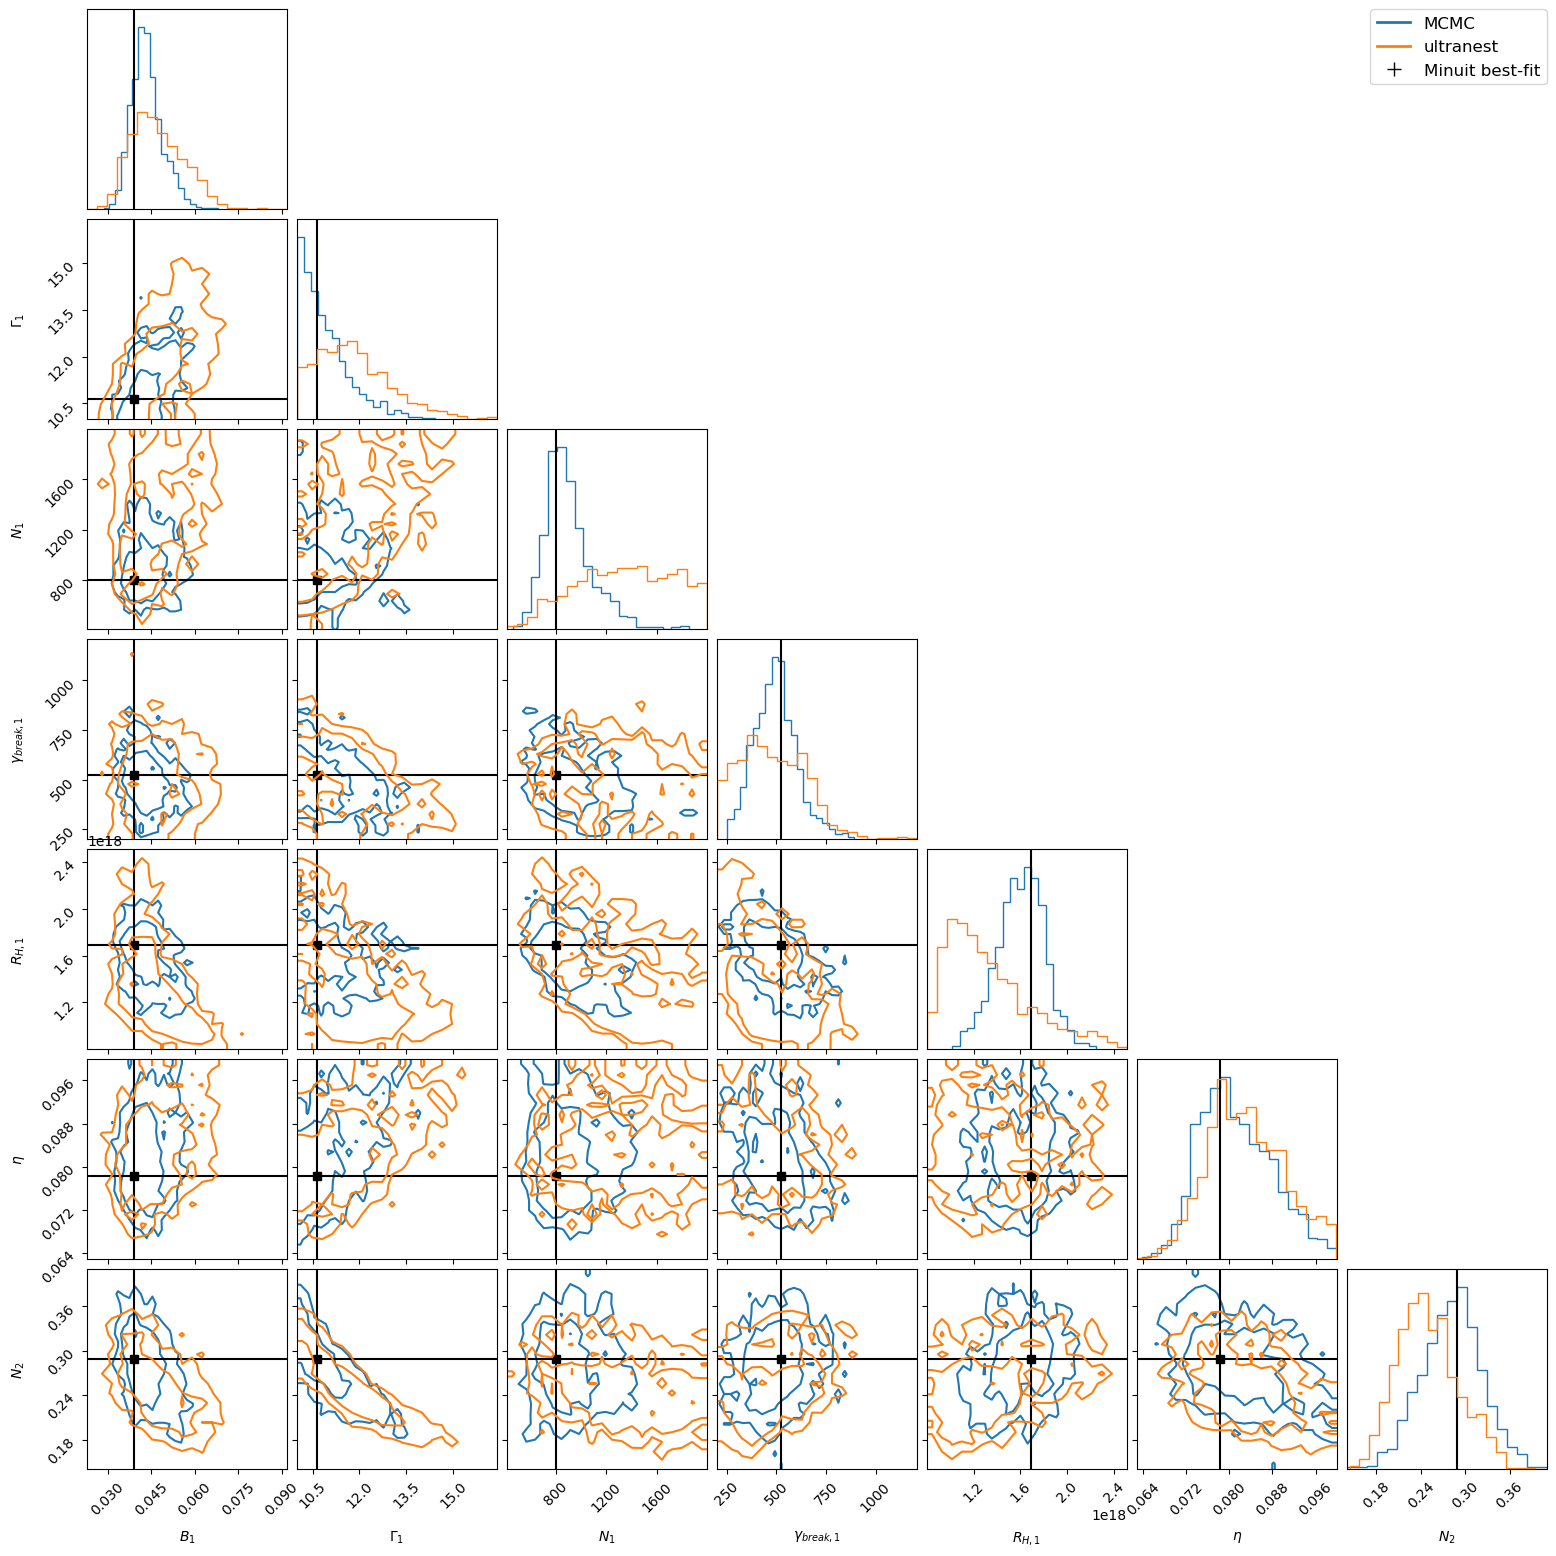

>>> Checkpoint 10.4: Overlaid corner plot saved -> three_way_corner.png
===> setting C threads to 8
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: T_DT to  T_DT
adding par: tau_DT to  tau_DT
adding par: R_inner_Sw to  R_inner_Sw
adding par: R_ext_Sw to  R_ext_Sw
adding par: accr_eff to  accr_eff
adding par: 

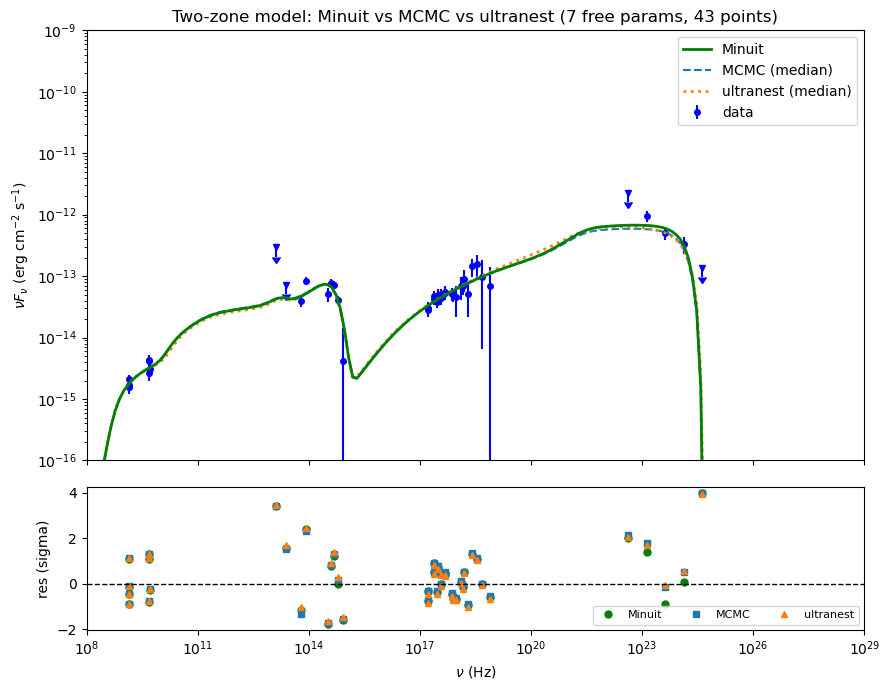

>>> Checkpoint 10.6: SED comparison saved -> three_way_sed_comparison.png

>>> PART 10 COMPLETE.
    Saved: three_way_corner.png, three_way_sed_comparison.png


In [28]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

free_params = (
    [('jet_leptonic', n) for n in
     ['B', 'BulkFactor', 'N', 'gamma_break', 'R_H', 'accr_eff']] +
    [('jet_extended', n) for n in ['N']]
)
param_labels = [r'$B_1$', r'$\Gamma_1$', r'$N_1$', r'$\gamma_{break,1}$',
                r'$R_{H,1}$', r'$\eta$', r'$N_2$']

# 1. Load data (43 points, top-2 Fermi excluded)
d = np.genfromtxt('../../../data/SED.txt')
d = d[d[:, 0] != 1.709E22]
d = d[~np.isin(d[:, 0], [1.324e25, 7.646e25])]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'MG3J163554+3629')

sed_data_43 = ObsData(data_table=data_obj)
sed_data_43.filter_data_set('-1', exclude=True)
sed_data_43.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data_43.table['nu_data'], freq, rtol=0.05)
    sed_data_43.table['UL'][mask] = True

nu_obs   = np.array(sed_data_43.table['nu_data'])
flux_obs = np.array(sed_data_43.table['nuFnu_data'])
flux_err = np.array(sed_data_43.table['dnuFnu_data'])
is_ul    = np.array(sed_data_43.table['UL'], dtype=bool)

print(">>> Checkpoint 10.1: Data loaded (43 points)")

# 2. Load Minuit best-fit
model_minuit = FitModel.load_model('TwoZone_7par_43pt.pkl')
model_minuit.eval()
minuit_vals = np.array([
    getattr(model_minuit, jet).parameters.get_par_by_name(name).val
    for jet, name in free_params
])
nu_minuit = np.array(model_minuit.SED.nu)
flux_minuit = np.array(model_minuit.SED.nuFnu)

print(">>> Checkpoint 10.2: Minuit best-fit loaded")
print(f"    values: {minuit_vals}")

# 3. Load MCMC and ultranest samples
import dill
with open('mcmc_7par_43pt.pkl', 'rb') as f:
    mcmc = dill.load(f)
mcmc_samples = np.asarray(mcmc.samples)

un_samples = np.loadtxt('ultranest_TwoZone_radio_reduced/chains/equal_weighted_post.txt',
                          skiprows=1)

print(f">>> Checkpoint 10.3: Samples loaded")
print(f"    MCMC samples shape: {mcmc_samples.shape}")
print(f"    ultranest samples shape: {un_samples.shape}")

# 4. Overlaid corner plot
try:
    import corner

    fig = corner.corner(
        mcmc_samples,
        labels=param_labels,
        color='C0',
        hist_kwargs={'density': True},
        plot_datapoints=False,
        plot_density=False,
        levels=(0.68, 0.95),
        truths=minuit_vals,
        truth_color='black',
        show_titles=False
    )

    corner.corner(
        un_samples,
        fig=fig,
        color='C1',
        hist_kwargs={'density': True},
        plot_datapoints=False,
        plot_density=False,
        levels=(0.68, 0.95),
        show_titles=False
    )

    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color='C0', lw=2, label='MCMC'),
        Line2D([0], [0], color='C1', lw=2, label='ultranest'),
        Line2D([0], [0], color='black', marker='+', linestyle='None',
               markersize=10, label='Minuit best-fit'),
    ]
    fig.legend(handles=legend_elements, loc='upper right', fontsize=12,
               bbox_to_anchor=(0.98, 0.98))

    plt.savefig('three_way_corner.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(">>> Checkpoint 10.4: Overlaid corner plot saved -> three_way_corner.png")
except ImportError:
    print("corner not installed -- skipping corner plot")

# 5. SED with all three model curves
def eval_at(params):
    m = FitModel.load_model('TwoZone_7par_43pt.pkl')
    for (jet, name), val in zip(free_params, params):
        getattr(m, jet).set_par(name, val=val)
    m.eval()
    return np.array(m.SED.nu), np.array(m.SED.nuFnu)

mcmc_median = np.median(mcmc_samples, axis=0)
un_median = np.median(un_samples, axis=0)

nu_mcmc, flux_mcmc = eval_at(mcmc_median)
nu_un, flux_un = eval_at(un_median)

print(">>> Checkpoint 10.5: All three model curves evaluated")

fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

good_minuit = flux_minuit > 0
good_mcmc = flux_mcmc > 0
good_un = flux_un > 0

ax.plot(nu_minuit[good_minuit], flux_minuit[good_minuit], '-', color='green',
        lw=2, label='Minuit', zorder=3)
ax.plot(nu_mcmc[good_mcmc], flux_mcmc[good_mcmc], '--', color='C0',
        lw=1.5, label='MCMC (median)', zorder=2)
ax.plot(nu_un[good_un], flux_un[good_un], ':', color='C1',
        lw=2, label='ultranest (median)', zorder=2)

ax.errorbar(nu_obs[~is_ul], flux_obs[~is_ul], yerr=flux_err[~is_ul], fmt='o',
             color='blue', ms=4, label='data', zorder=1)
ax.errorbar(nu_obs[is_ul], flux_obs[is_ul], yerr=flux_obs[is_ul]*0.3, fmt='v',
             color='blue', ms=4, uplims=True, zorder=1)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-16, 1e-9)
ax.set_xlim(1e8, 1e29)
ax.set_ylabel(r'$\nu F_\nu$ (erg cm$^{-2}$ s$^{-1}$)')
ax.legend(fontsize=10)
ax.set_title('Two-zone model: Minuit vs MCMC vs ultranest (7 free params, 43 points)')

# Residuals
def residuals(nu_grid, flux_grid):
    good = flux_grid > 0
    idx = np.argsort(nu_grid[good])
    model_at_data = np.interp(nu_obs, nu_grid[good][idx], flux_grid[good][idx],
                               left=0., right=0.)
    return (flux_obs - model_at_data) / flux_err

res_minuit = residuals(nu_minuit, flux_minuit)
res_mcmc = residuals(nu_mcmc, flux_mcmc)
res_un = residuals(nu_un, flux_un)

axr.plot(nu_obs, res_minuit, 'o', color='green', ms=5, label='Minuit')
axr.plot(nu_obs, res_mcmc, 's', color='C0', ms=4, label='MCMC')
axr.plot(nu_obs, res_un, '^', color='C1', ms=4, label='ultranest')
axr.axhline(0, color='k', ls='--', lw=1)
axr.set_xscale('log')
axr.set_xlabel(r'$\nu$ (Hz)')
axr.set_ylabel('res (sigma)')
axr.legend(fontsize=8, ncol=3)

plt.tight_layout()
plt.savefig('three_way_sed_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(">>> Checkpoint 10.6: SED comparison saved -> three_way_sed_comparison.png")

print("\n>>> PART 10 COMPLETE.")
print("    Saved: three_way_corner.png, three_way_sed_comparison.png")